In [9]:
import os
import h5py as h5
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
NSHM_ruptures_branch = "../data/crustal_solutions/NZSHM22_InversionSolution-QXV0b21hdGlvblRhc2s6MTA3MDE5"
NSHM_ruptures_branch = "../data/sz_solutions/NZSHM22_ScaledInversionSolution-QXV0b21hdGlvblRhc2s6MTMyNzM5NQ=="
NSHM_ruptures_csv = f"{NSHM_ruptures_branch}/ruptures/properties.csv"
NSHM_rates_csv = f"{NSHM_ruptures_branch}/solution/rates.csv"

ruptures = pd.read_csv(NSHM_ruptures_csv)
rates = pd.read_csv(NSHM_rates_csv)
ruptures = ruptures[rates["Annual Rate"] > 0]
ruptures

,Rupture Index,Magnitude,Average Rake (degrees),Area (m^2),Length (m)
3,3,7.049840,90.0,1.121615e+09,74774.316320
4,4,7.253993,90.0,1.794720e+09,59820.533812
5,5,7.350896,90.0,2.243362e+09,74774.316320
6,6,7.430071,90.0,2.691999e+09,89727.567284
7,7,7.497005,90.0,3.140573e+09,104679.226899
...,...,...,...,...,...
15773,15773,7.252963,90.0,1.790469e+09,74594.197571
15779,15779,7.048654,90.0,1.118555e+09,74570.324405
15781,15781,7.303978,90.0,2.013639e+09,74570.324405
15785,15785,7.127997,90.0,1.342767e+09,59672.276113


In [11]:
rupture = ruptures.loc[ruptures['Magnitude'] == ruptures["Magnitude"].max(), "Rupture Index"].values[0]

In [15]:
results_dir = f"../results/CFM/sites_c_{NSHM_ruptures_branch[-4:]}"
results_dir = f"../results/puysegur/sites_py_{NSHM_ruptures_branch[-6:-2]}"
branch_h5 = h5.File(f"{results_dir}/all_rupture_disps_{os.path.basename(results_dir)}.h5", 'r')

In [16]:
coords = branch_h5['site_coords'][:]
coords

array([[1159317., 4862761.],
       [1404397., 4911879.],
       [1373751., 4878626.],
       ...,
       [1332000., 5001000.],
       [1323000., 5001000.],
       [1188000., 4758000.]])

In [17]:
v_disps = branch_h5[str(rupture)]['v_disps_m'][:]

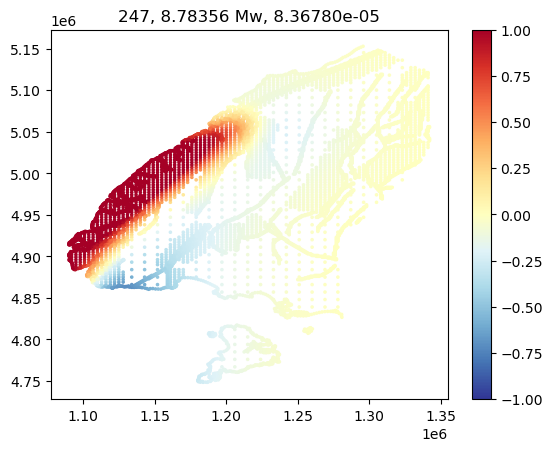

In [18]:
plt.scatter(coords[v_disps[:, 0].astype(int), 0], coords[v_disps[:, 0].astype(int), 1], c=v_disps[:, 1], s=2.5, vmin=-1, vmax=1, cmap="RdYlBu_r")
plt.title(f"{rupture}, {ruptures.loc[ruptures['Magnitude'] == ruptures['Magnitude'].max(), 'Magnitude'].values[0]:.05f} Mw, {rates.loc[rupture]['Annual Rate']:.05e}")
plt.colorbar()

In [19]:
branch_h5.close()